# NIST23 Data Quality Analysis

Characterises intrinsic spectrum quality using peak positions, precursor mass, and molecular formula.
Independent of the fragmentation model — uses mbfs_prepass wrecall as a proxy for DAG coverage
to separate model gaps from noisy-spectrum issues.

In [1]:
import io
import tarfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FRAG_DP = Path("../data/frag")
PROC_DP = Path("../data/proc/nist23")

In [2]:
# Load mbfs_prepass wrecall columns
MBFS_PREPASS_PATH = FRAG_DP / "nist23_ma_mi_d3_h4_isoFalse_mbfs_prepass"

W4 = "wrecall_0.01_h4"
W2 = "wrecall_0.01_h2"

spec_stats_path = MBFS_PREPASS_PATH / "spec_stats_df.pkl"
pp_stats = pd.read_pickle(spec_stats_path)[["spec_id", W4, W2]].copy()
pp_stats["spec_id"] = pp_stats["spec_id"].astype(int)
print(f"pp_stats: {pp_stats.shape}")

pp_stats: (804966, 3)


In [3]:
# Load nist23 spec metadata
spec_meta = pd.read_pickle(PROC_DP / "spec_df.pkl")[
    ["spec_id", "mol_id", "inst_type", "frag_mode", "prec_type",
     "ion_mode", "ace", "nce", "peaks"]
].copy()
spec_meta["num_peaks"] = spec_meta["peaks"].apply(
    lambda x: len(x) if x is not None else 0
)
spec_meta = spec_meta.drop(columns=["peaks"])
print(f"spec_meta: {spec_meta.shape}")

# Join and create quality tiers by wrecall_h4
merged = pp_stats.merge(spec_meta, on="spec_id", how="left")
print(f"merged: {merged.shape}  unmatched: {merged['inst_type'].isna().sum():,}")

TIER_ORDER = ["very_low (<0.1)", "low (0.1-0.3)", "medium (0.3-0.5)", "good (>0.5)"]
merged["quality"] = pd.cut(
    merged[W4],
    bins=[-0.001, 0.1, 0.3, 0.5, 1.001],
    labels=TIER_ORDER,
)
TIER_COLORS = {
    "very_low (<0.1)": "tab:red",
    "low (0.1-0.3)": "tab:orange",
    "medium (0.3-0.5)": "tab:blue",
    "good (>0.5)": "tab:green",
}
print("\nQuality tier counts:")
print(merged["quality"].value_counts().sort_index())

spec_meta: (1899597, 9)
merged: (804966, 11)  unmatched: 0

Quality tier counts:
quality
very_low (<0.1)      16195
low (0.1-0.3)        23466
medium (0.3-0.5)     32136
good (>0.5)         733169
Name: count, dtype: int64


## NIST Data Quality Analysis

Independent of the fragmentation model — characterises intrinsic spectrum quality using peak positions, precursor mass, and molecular formula.

In [4]:
# A. Mol metadata join + B/D. Peak quality feature extraction
# ---------------------------------------------------------------
# Joins exact_mw / num_atoms from mol_df, then computes per-spectrum:
#   frac_below_prec   – fraction of peaks with m/z ≤ prec_mz + 1.5
#   n_above_prec      – count of peaks with m/z > prec_mz + 2 Da (above precursor → noise)
#   has_prec_peak     – any peak within 0.02 Da of prec_mz (unfragmented leakthrough)
#   intensity_entropy – -Σ p·log(p) over normalised intensities

mol_df_meta = pd.read_pickle(PROC_DP / "mol_df.pkl")[["mol_id", "formula", "exact_mw", "num_atoms"]]
merged = merged.merge(mol_df_meta, on="mol_id", how="left")

spec_ids_needed = set(merged["spec_id"].values)
spec_sub = pd.read_pickle(PROC_DP / "spec_df.pkl")[["spec_id", "prec_mz", "peaks"]]
spec_sub = spec_sub[spec_sub["spec_id"].isin(spec_ids_needed)].reset_index(drop=True)


def compute_peak_feats(row: pd.Series) -> tuple:
    peaks = row["peaks"]
    prec_mz = row["prec_mz"]
    if not peaks or prec_mz != prec_mz:  # empty or NaN
        return (np.nan, np.nan, False, np.nan)
    mzs = np.fromiter((p[0] for p in peaks), dtype=float, count=len(peaks))
    ints = np.fromiter((p[1] for p in peaks), dtype=float, count=len(peaks))
    frac_below = float((mzs <= prec_mz + 1.5).mean())
    n_above = int((mzs > prec_mz + 2.0).sum())
    has_prec = bool((np.abs(mzs - prec_mz) <= 0.02).any())
    p = ints / ints.sum()
    p = p[p > 0]
    entropy = float(-np.sum(p * np.log(p)))
    return (frac_below, n_above, has_prec, entropy)


print("Computing peak features…")
feat_cols = ["frac_below_prec", "n_above_prec", "has_prec_peak", "intensity_entropy"]
feat_df = spec_sub.apply(compute_peak_feats, axis=1, result_type="expand")
feat_df.columns = feat_cols
feat_df["spec_id"] = spec_sub["spec_id"].values
merged = merged.merge(feat_df[["spec_id"] + feat_cols], on="spec_id", how="left")
print("Done. merged shape:", merged.shape)
print(merged[feat_cols].describe().round(3))

Computing peak features…
Done. merged shape: (804966, 19)
       frac_below_prec  n_above_prec  intensity_entropy
count       804966.000    804966.000         804966.000
mean             0.998         0.025              1.681
std              0.019         0.286              1.061
min              0.333         0.000             -0.000
25%              1.000         0.000              0.824
50%              1.000         0.000              1.485
75%              1.000         0.000              2.390
max              1.000        87.000              6.125


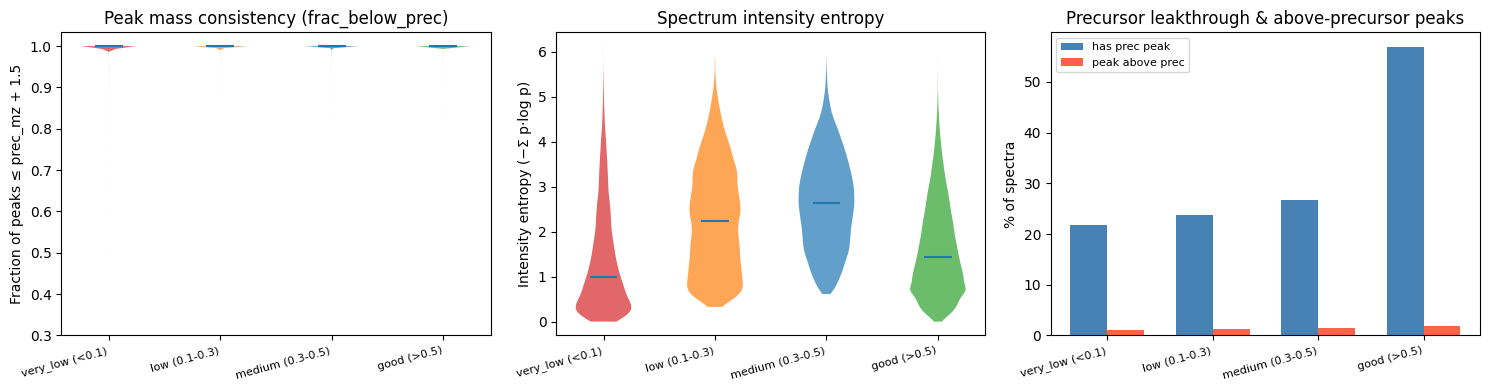

In [5]:
# D. Peak quality flags by quality tier
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (1) frac_below_prec violin
ax = axes[0]
data = [merged.loc[merged["quality"] == t, "frac_below_prec"].dropna().values for t in TIER_ORDER]
parts = ax.violinplot(data, positions=range(len(TIER_ORDER)), showmedians=True, showextrema=False)
for i, (pc, t) in enumerate(zip(parts["bodies"], TIER_ORDER)):
    pc.set_facecolor(TIER_COLORS[t])
    pc.set_alpha(0.7)
ax.set_xticks(range(len(TIER_ORDER)))
ax.set_xticklabels(TIER_ORDER, rotation=15, ha="right", fontsize=8)
ax.set_ylabel("Fraction of peaks ≤ prec_mz + 1.5")
ax.set_title("Peak mass consistency (frac_below_prec)")

# (2) intensity_entropy violin
ax = axes[1]
data = [merged.loc[merged["quality"] == t, "intensity_entropy"].dropna().values for t in TIER_ORDER]
parts = ax.violinplot(data, positions=range(len(TIER_ORDER)), showmedians=True, showextrema=False)
for pc, t in zip(parts["bodies"], TIER_ORDER):
    pc.set_facecolor(TIER_COLORS[t])
    pc.set_alpha(0.7)
ax.set_xticks(range(len(TIER_ORDER)))
ax.set_xticklabels(TIER_ORDER, rotation=15, ha="right", fontsize=8)
ax.set_ylabel("Intensity entropy (−Σ p·log p)")
ax.set_title("Spectrum intensity entropy")

# (3) has_prec_peak & n_above_prec rates as grouped bar
ax = axes[2]
rates = {}
rates["has_prec_peak (%)"] = [
    merged.loc[merged["quality"] == t, "has_prec_peak"].mean() * 100 for t in TIER_ORDER
]
rates["n_above_prec > 0 (%)"] = [
    (merged.loc[merged["quality"] == t, "n_above_prec"] > 0).mean() * 100 for t in TIER_ORDER
]
x = np.arange(len(TIER_ORDER))
width = 0.35
ax.bar(x - width / 2, rates["has_prec_peak (%)"], width, label="has prec peak", color="steelblue")
ax.bar(x + width / 2, rates["n_above_prec > 0 (%)"], width, label="peak above prec", color="tomato")
ax.set_xticks(x)
ax.set_xticklabels(TIER_ORDER, rotation=15, ha="right", fontsize=8)
ax.set_ylabel("% of spectra")
ax.set_title("Precursor leakthrough & above-precursor peaks")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

Quadrant counts (n=804,966):
  noisy+bad  (LL):  1,139  0.1%
  clean+bad  (LR): 139,451  17.3%  ← DAG gap, fixable
  noisy+good (UL): 11,745  1.5%
  clean+good (UR): 652,631  81.1%  ← ideal


/tmp/ipykernel_33472/1486227861.py:51: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/feiw/miniconda3/envs/FRAGNNET-GPU/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


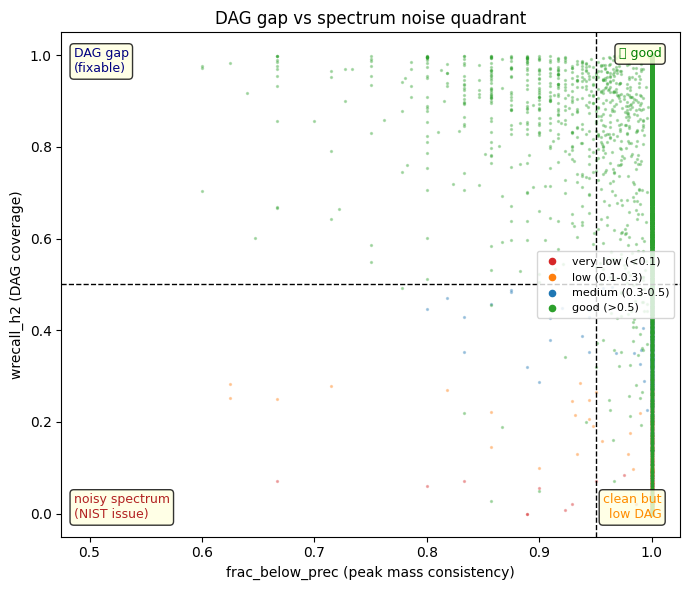

In [6]:
# C. Quadrant: DAG gap vs spectrum noise
# x-axis: frac_below_prec  (formula/mass-consistent peaks — intrinsic quality)
# y-axis: wrecall_h2        (DAG coverage — model quality)
# Quadrant thresholds: x > 0.95 = "clean spectrum", y > 0.5 = "good DAG coverage"
THRESHOLD_X = 0.95
THRESHOLD_Y = 0.5

plot_df = merged[["frac_below_prec", W2, "quality"]].dropna()
# Sample for scatter legibility
sample = plot_df.sample(min(30_000, len(plot_df)), random_state=42)

fig, ax = plt.subplots(figsize=(7, 6))
for tier in TIER_ORDER:
    sub = sample[sample["quality"] == tier]
    ax.scatter(sub["frac_below_prec"], sub[W2], s=2, alpha=0.3, color=TIER_COLORS[tier], label=tier)

ax.axvline(THRESHOLD_X, color="k", lw=1, ls="--")
ax.axhline(THRESHOLD_Y, color="k", lw=1, ls="--")

# Quadrant labels
ax.text(0.02, 0.97, "DAG gap\n(fixable)", transform=ax.transAxes,
        ha="left", va="top", fontsize=9, color="navy",
        bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", alpha=0.8))
ax.text(0.97, 0.97, "\u2705 good", transform=ax.transAxes,
        ha="right", va="top", fontsize=9, color="green",
        bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", alpha=0.8))
ax.text(0.02, 0.03, "noisy spectrum\n(NIST issue)", transform=ax.transAxes,
        ha="left", va="bottom", fontsize=9, color="firebrick",
        bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", alpha=0.8))
ax.text(0.97, 0.03, "clean but\nlow DAG", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=9, color="darkorange",
        bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", alpha=0.8))

# Quadrant counts on full data
q_ll = ((plot_df["frac_below_prec"] <= THRESHOLD_X) & (plot_df[W2] <= THRESHOLD_Y)).sum()
q_lr = ((plot_df["frac_below_prec"] > THRESHOLD_X) & (plot_df[W2] <= THRESHOLD_Y)).sum()
q_ul = ((plot_df["frac_below_prec"] <= THRESHOLD_X) & (plot_df[W2] > THRESHOLD_Y)).sum()
q_ur = ((plot_df["frac_below_prec"] > THRESHOLD_X) & (plot_df[W2] > THRESHOLD_Y)).sum()
total = len(plot_df)
print(f"Quadrant counts (n={total:,}):")
print(f"  noisy+bad  (LL): {q_ll:6,}  {100*q_ll/total:.1f}%")
print(f"  clean+bad  (LR): {q_lr:6,}  {100*q_lr/total:.1f}%  ← DAG gap, fixable")
print(f"  noisy+good (UL): {q_ul:6,}  {100*q_ul/total:.1f}%")
print(f"  clean+good (UR): {q_ur:6,}  {100*q_ur/total:.1f}%  ← ideal")

handles = [plt.scatter([], [], s=20, color=TIER_COLORS[t], label=t) for t in TIER_ORDER]
ax.legend(handles=handles, fontsize=8, loc="center right")
ax.set_xlabel("frac_below_prec (peak mass consistency)")
ax.set_ylabel(f"wrecall_h2 (DAG coverage)")
ax.set_title("DAG gap vs spectrum noise quadrant")
plt.tight_layout()
plt.show()

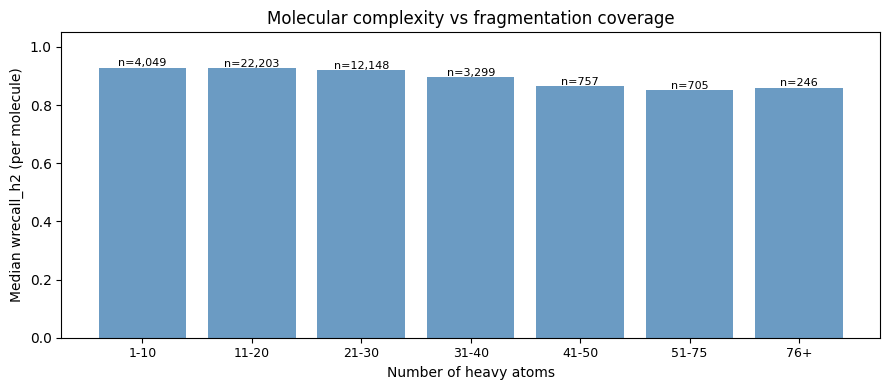

In [7]:
# E. Molecular complexity vs wrecall
# Bin molecules by num_atoms; show median wrecall_h2 per bin + count annotation

mol_wrecall = (
    merged.dropna(subset=["num_atoms", W2])
    .groupby("mol_id")
    .agg(num_atoms=("num_atoms", "first"), med_wrecall=(W2, "median"), n_specs=(W2, "count"))
    .reset_index()
)

BINS = [0, 10, 20, 30, 40, 50, 75, 150]
LABELS = ["1-10", "11-20", "21-30", "31-40", "41-50", "51-75", "76+"]
mol_wrecall["atom_bin"] = pd.cut(mol_wrecall["num_atoms"], bins=BINS, labels=LABELS)

bin_stats = mol_wrecall.groupby("atom_bin", observed=True).agg(
    median_wrecall=("med_wrecall", "median"),
    n_mols=("mol_id", "count"),
).reset_index()

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(range(len(bin_stats)), bin_stats["median_wrecall"], color="steelblue", alpha=0.8)
for i, (_, row) in enumerate(bin_stats.iterrows()):
    ax.text(i, row["median_wrecall"] + 0.005, f"n={row['n_mols']:,}", ha="center", fontsize=8)

ax.set_xticks(range(len(bin_stats)))
ax.set_xticklabels(bin_stats["atom_bin"], fontsize=9)
ax.set_xlabel("Number of heavy atoms")
ax.set_ylabel("Median wrecall_h2 (per molecule)")
ax.set_title("Molecular complexity vs fragmentation coverage")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()